In [1]:
# Setup
import os
os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")
os.environ.setdefault("OMP_NUM_THREADS", "1")

import json
import numpy as np
import pandas as pd
import h5py
import matplotlib.pyplot as plt
import torch
from chronos import Chronos2Pipeline

USE_FINETUNED = False

device = "cuda" if torch.cuda.is_available() else "cpu"
if USE_FINETUNED:
    MODEL_LABEL = "Chronos-2 fine-tuned"
    pipeline = Chronos2Pipeline.from_pretrained("chronos-2-tep-finetuned", device_map=device,
                                                import_allowlist=["chronos.chronos2.model"])
else:
    MODEL_LABEL = "Chronos-2"
    pipeline = Chronos2Pipeline.from_pretrained("amazon/chronos-2", device_map=device)

MAX_CONTEXT = pipeline.model_context_length
print(f"Loaded {MODEL_LABEL} on {device}, max context {MAX_CONTEXT} samples")

Loading weights:   0%|          | 0/170 [00:00<?, ?it/s]

Loaded Chronos-2 on cpu, max context 8192 samples


In [2]:
# Load data
DATA_FILE = "tep_sp_spaced_6min_noisy.h5"

f = h5py.File(DATA_FILE, "r")
config = json.loads(f.attrs["config"])

data = {"time_h": f["t"][()] / 3600}
LABELS = {}

for group in ["xmeas", "xmv", "sp", "dist"]:
    values = f[group][()]
    names = f[group].attrs["names"]
    for i in range(values.shape[1]):
        col = f"{group}_{i + 1}"
        data[col] = values[:, i]
        LABELS[col] = str(names[i].decode() if isinstance(names[i], bytes) else names[i])

valves = f["y"][:, 38:50]   # true valve positions
for i in range(12):
    data[f"valve_{i + 1}"] = valves[:, i]
    LABELS[f"valve_{i + 1}"] = f"Valve {i + 1} position"
f.close()

df = pd.DataFrame(data)
df["item_id"] = "tep"
df["timestamp"] = pd.date_range("2026-01-01", periods=len(df), freq=f"{config['record_every']}s")

# Set points changed in this run, and where any of them is off nominal
nominal = {int(k): v for k, v in config["setpoints"].items()}
CHANGED = sorted({k for k, _, _ in config["setpoint_schedule"]})
df["off_nominal"] = False
for k in CHANGED:
    df["off_nominal"] = df["off_nominal"] | (np.abs(df[f"sp_{k}"] - nominal[k]) > 1e-9)

print(f"{len(df)} samples ({df['time_h'].iloc[-1]:.0f} h), changed set points: {CHANGED}")
print(f"test part from {config.get('t_test')} h")

6798 samples (680 h), changed set points: [5, 7, 8, 11, 13, 14, 15, 17, 18, 19, 20]
test part from 580.6 h


In [3]:
# Pick a forecast window
# Set point excursions
events = []
for k in CHANGED:
    off = (np.abs(df[f"sp_{k}"] - nominal[k]) > 1e-9).to_numpy()
    for i in range(len(off)):
        if off[i] and (i == 0 or not off[i - 1]):
            start = i
        if off[i] and (i == len(off) - 1 or not off[i + 1]):
            events.append((start, i, k))
events.sort()

for n, (s, e, k) in enumerate(events):
    print(f"{n:2d}  SP {k:2d}  samples {s:4d}-{e:4d}  ({df['time_h'][s]:5.1f}-{df['time_h'][e]:5.1f} h)  "
          f"{nominal[k]:.4g} -> {df[f'sp_{k}'][s]:.4g}  {LABELS[f'sp_{k}']}")

EVENT_INDEX = 71
BUFFER = 20
HORIZON = 50        # forecast length in samples
PLOT_LEAD_IN = 200

event_start, event_end, event_sp = events[EVENT_INDEX]
SPLIT = event_start - BUFFER                # first forecast sample
CONTEXT_START = max(SPLIT - MAX_CONTEXT, 0)
print(f"\nForecast samples {SPLIT}-{SPLIT + HORIZON - 1}, context samples {CONTEXT_START}-{SPLIT - 1}")

 0  SP 14  samples   99- 148  ( 10.0- 14.9 h)  6.882 -> 7.282  Reactor feed D (mol%)
 1  SP 18  samples  201- 220  ( 20.2- 22.1 h)  120.4 -> 121.5  Reactor temperature (C)
 2  SP 19  samples  247- 296  ( 24.8- 29.7 h)  13.82 -> 12.42  Purge B (mol%)
 3  SP 17  samples  355- 394  ( 35.6- 39.5 h)  75 -> 75.88  Reactor level (%)
 4  SP  8  samples  437- 456  ( 43.8- 45.7 h)  50 -> 55.6  Stripper level (%)
 5  SP 13  samples  480- 529  ( 48.1- 53.0 h)  32.19 -> 33.39  Reactor feed A (mol%)
 6  SP 11  samples  589- 628  ( 59.0- 62.9 h)  22.95 -> 23.23  Stripper underflow (m3/h)
 7  SP 17  samples  675- 714  ( 67.6- 71.5 h)  75 -> 73.25  Reactor level (%)
 8  SP 14  samples  760- 809  ( 76.1- 81.0 h)  6.882 -> 6.602  Reactor feed D (mol%)
 9  SP 17  samples  867- 906  ( 86.8- 90.7 h)  75 -> 72.5  Reactor level (%)
10  SP 17  samples  952- 991  ( 95.3- 99.2 h)  75 -> 74.12  Reactor level (%)
11  SP  8  samples 1042-1061  (104.3-106.2 h)  50 -> 42  Stripper level (%)
12  SP  5  samples 1090-11

In [4]:
# Targets
XMEAS_TARGETS = [1, 2, 3, 6, 7, 8, 9, 16, 21, 23, 24, 25, 26, 27, 28]   # reactor
# XMEAS_TARGETS = list(range(1, 42))                                   # all 41 measurements

XMV_TARGETS = [1, 2, 3, 10, 12]      # reactor valves
# XMV_TARGETS = list(range(1, 13))   # all 12 valves

TARGETS = [f"xmeas_{i}" for i in XMEAS_TARGETS] + [f"xmv_{i}" for i in XMV_TARGETS]
print(f"targets ({len(TARGETS)}): {TARGETS}")

targets (20): ['xmeas_1', 'xmeas_2', 'xmeas_3', 'xmeas_6', 'xmeas_7', 'xmeas_8', 'xmeas_9', 'xmeas_16', 'xmeas_21', 'xmeas_23', 'xmeas_24', 'xmeas_25', 'xmeas_26', 'xmeas_27', 'xmeas_28', 'xmv_1', 'xmv_2', 'xmv_3', 'xmv_10', 'xmv_12']


In [5]:
# Past covariates
PAST_XMEAS = []
# PAST_XMEAS = [4, 5, 13, 14, 18, 29, 30, 31, 32, 33, 34, 35, 36]   # reactor inputs from the other sections

PAST_SP = []
# PAST_SP = [5, 7, 8, 11, 13, 14, 15, 17, 18, 19, 20]   # all changed set points

PAST_DIST = []
# PAST_DIST = [1, 2, 3, 5, 7, 8, 10, 12]   # reactor disturbances

PAST_VALVE = []
# PAST_VALVE = [1, 2, 3, 10]   # true positions of the reactor valves

PAST_COVARIATES = ([f"xmeas_{i}" for i in PAST_XMEAS] + [f"sp_{i}" for i in PAST_SP]
                   + [f"dist_{i}" for i in PAST_DIST] + [f"valve_{i}" for i in PAST_VALVE])
print(f"past covariates ({len(PAST_COVARIATES)}): {PAST_COVARIATES}")

past covariates (0): []


In [6]:
# Future covariates
FUTURE_SP = [5, 7, 8, 11, 13, 14, 15, 17, 18, 19, 20]   # all changed set points
# FUTURE_SP = [13, 14, 15, 17, 18]                      # reactor set points only

FUTURE_XMEAS = []
# FUTURE_XMEAS = [4, 5, 13, 14, 18, 29, 30, 31, 32, 33, 34, 35, 36]   # other sections

FUTURE_DIST = []
# FUTURE_DIST = [1, 2, 3, 5, 7, 8, 10, 12]   # reactor disturbances

FUTURE_COVARIATES = ([f"sp_{i}" for i in FUTURE_SP] + [f"xmeas_{i}" for i in FUTURE_XMEAS]
                     + [f"dist_{i}" for i in FUTURE_DIST])
print(f"future covariates ({len(FUTURE_COVARIATES)}): {FUTURE_COVARIATES}")

future covariates (11): ['sp_5', 'sp_7', 'sp_8', 'sp_11', 'sp_13', 'sp_14', 'sp_15', 'sp_17', 'sp_18', 'sp_19', 'sp_20']


In [ ]:
# Build the model inputs
context_df = df.iloc[CONTEXT_START:SPLIT]
truth_df = df.iloc[SPLIT:SPLIT + HORIZON]         # actual values over the forecast horizon

model_context_df = context_df[["item_id", "timestamp"] + TARGETS + PAST_COVARIATES + FUTURE_COVARIATES]
model_future_df = truth_df[["item_id", "timestamp"] + FUTURE_COVARIATES]

display(model_context_df.tail())
display(model_future_df.head()) 

,item_id,timestamp,xmeas_1,xmeas_2,xmeas_3,xmeas_6,xmeas_7,xmeas_8,xmeas_9,xmeas_16,...,sp_7,sp_8,sp_11,sp_13,sp_14,sp_15,sp_17,sp_18,sp_19,sp_20
6194,tep,2026-01-26 19:24:00,0.274806,3705.550011,4600.720533,42.535915,2705.749078,75.004355,121.154189,3107.790822,...,50.0,50.0,22.949,32.188,6.882,18.776,75.0,120.4,13.823,0.8357
6195,tep,2026-01-26 19:30:00,0.298789,3664.815260,4584.047606,42.118376,2715.908023,75.634078,120.537835,3114.723443,...,50.0,50.0,22.949,32.188,6.882,18.776,75.0,120.4,13.823,0.8357
6196,tep,2026-01-26 19:36:00,0.285826,3685.136510,4560.594714,42.081753,2712.389256,75.117727,120.404073,3112.092884,...,50.0,50.0,22.949,32.188,6.882,18.776,75.0,120.4,13.823,0.8357
6197,tep,2026-01-26 19:42:00,0.336394,3696.440016,4569.038656,42.421324,2710.200871,75.235047,120.381489,3110.035951,...,50.0,50.0,22.949,32.188,6.882,18.776,75.0,120.4,13.823,0.8357
6198,tep,2026-01-26 19:48:00,0.276505,3652.031755,4580.085103,42.482507,2712.815012,75.216157,120.412227,3110.092708,...,50.0,50.0,22.949,32.188,6.882,18.776,75.0,120.4,13.823,0.8357


,item_id,timestamp,sp_5,sp_7,sp_8,sp_11,sp_13,sp_14,sp_15,sp_17,sp_18,sp_19,sp_20
6199,tep,2026-01-26 19:54:00,26.902,50.0,50.0,22.949,32.188,6.882,18.776,75.0,120.4,13.823,0.8357
6200,tep,2026-01-26 20:00:00,26.902,50.0,50.0,22.949,32.188,6.882,18.776,75.0,120.4,13.823,0.8357
6201,tep,2026-01-26 20:06:00,26.902,50.0,50.0,22.949,32.188,6.882,18.776,75.0,120.4,13.823,0.8357
6202,tep,2026-01-26 20:12:00,26.902,50.0,50.0,22.949,32.188,6.882,18.776,75.0,120.4,13.823,0.8357
6203,tep,2026-01-26 20:18:00,26.902,50.0,50.0,22.949,32.188,6.882,18.776,75.0,120.4,13.823,0.8357


In [8]:
# Run Chronos-2
pred_df = pipeline.predict_df(
    model_context_df,
    future_df=model_future_df if FUTURE_COVARIATES else None,
    prediction_length=HORIZON,
    quantile_levels=[0.1, 0.5, 0.9],
    id_column="item_id",
    timestamp_column="timestamp",
    target=TARGETS,
)

# Forecast, lower and upper bound per target
forecast, lower, upper = {}, {}, {}
for col in TARGETS:
    sub = pred_df[pred_df["target_name"] == col]
    forecast[col] = sub["predictions"].to_numpy()
    lower[col] = sub["0.1"].to_numpy()
    upper[col] = sub["0.9"].to_numpy()

In [9]:
# Accuracy
in_fault = truth_df["off_nominal"].to_numpy()
normal_context = context_df[~context_df["off_nominal"]]

rows = []
for col in TARGETS:
    actual = truth_df[col].to_numpy()
    scale = normal_context[col].std()
    if scale == 0:
        scale = np.nan
    err = np.abs(forecast[col] - actual) / scale
    base_err = np.abs(context_df[col].iloc[-1] - actual) / scale
    rows.append({
        "variable": col,
        "description": LABELS[col],
        "MAE": np.abs(forecast[col] - actual).mean(),
        "scaled MAE (nominal)": err[~in_fault].mean(),
        "scaled MAE (off nominal)": err[in_fault].mean(),
        "scaled MAE (all)": err.mean(),
        "baseline (nominal)": base_err[~in_fault].mean(),
        "baseline (off nominal)": base_err[in_fault].mean(),
        "baseline (all)": base_err.mean(),
    })
accuracy = pd.DataFrame(rows).set_index("variable")

for phase in ["nominal", "off nominal", "all"]:
    print(f"{phase:12s}  {MODEL_LABEL}: {accuracy[f'scaled MAE ({phase})'].mean():.3f}   "
          f"baseline: {accuracy[f'baseline ({phase})'].mean():.3f}")
accuracy.sort_values("scaled MAE (all)", ascending=False).round(4)

nominal       Chronos-2: 0.681   baseline: 0.889
off nominal   Chronos-2: 0.676   baseline: 1.161
all           Chronos-2: 0.678   baseline: 1.052


,description,MAE,scaled MAE (nominal),scaled MAE (off nominal),scaled MAE (all),baseline (nominal),baseline (off nominal),baseline (all)
variable,,,,,,,,
xmeas_7,Reactor pressure (kPa),23.5142,0.8736,0.8111,0.8361,1.0235,1.3776,1.2359
xmv_2,E feed flow,0.7097,0.7942,0.8512,0.8284,1.1920,1.4318,1.3359
xmeas_8,Reactor level (%),0.6732,0.7170,0.8874,0.8193,0.8656,1.2073,1.0706
xmeas_3,E feed (kg/h),57.3620,0.7606,0.8260,0.7998,1.4177,1.7160,1.5967
xmeas_25,Reactor feed C (mol%),0.6329,0.9894,0.6613,0.7926,1.3288,1.2360,1.2731
xmv_3,A feed flow,5.3634,0.7792,0.7595,0.7674,0.8442,1.2100,1.0637
xmeas_1,A feed (kscmh),0.0544,0.7829,0.7559,0.7667,0.8467,1.2149,1.0676
xmeas_6,Reactor feed rate (kscmh),0.1832,0.5825,0.8698,0.7549,0.9834,1.0422,1.0187
xmeas_27,Reactor feed E (mol%),0.4204,0.9144,0.6214,0.7386,0.8068,1.7624,1.3802


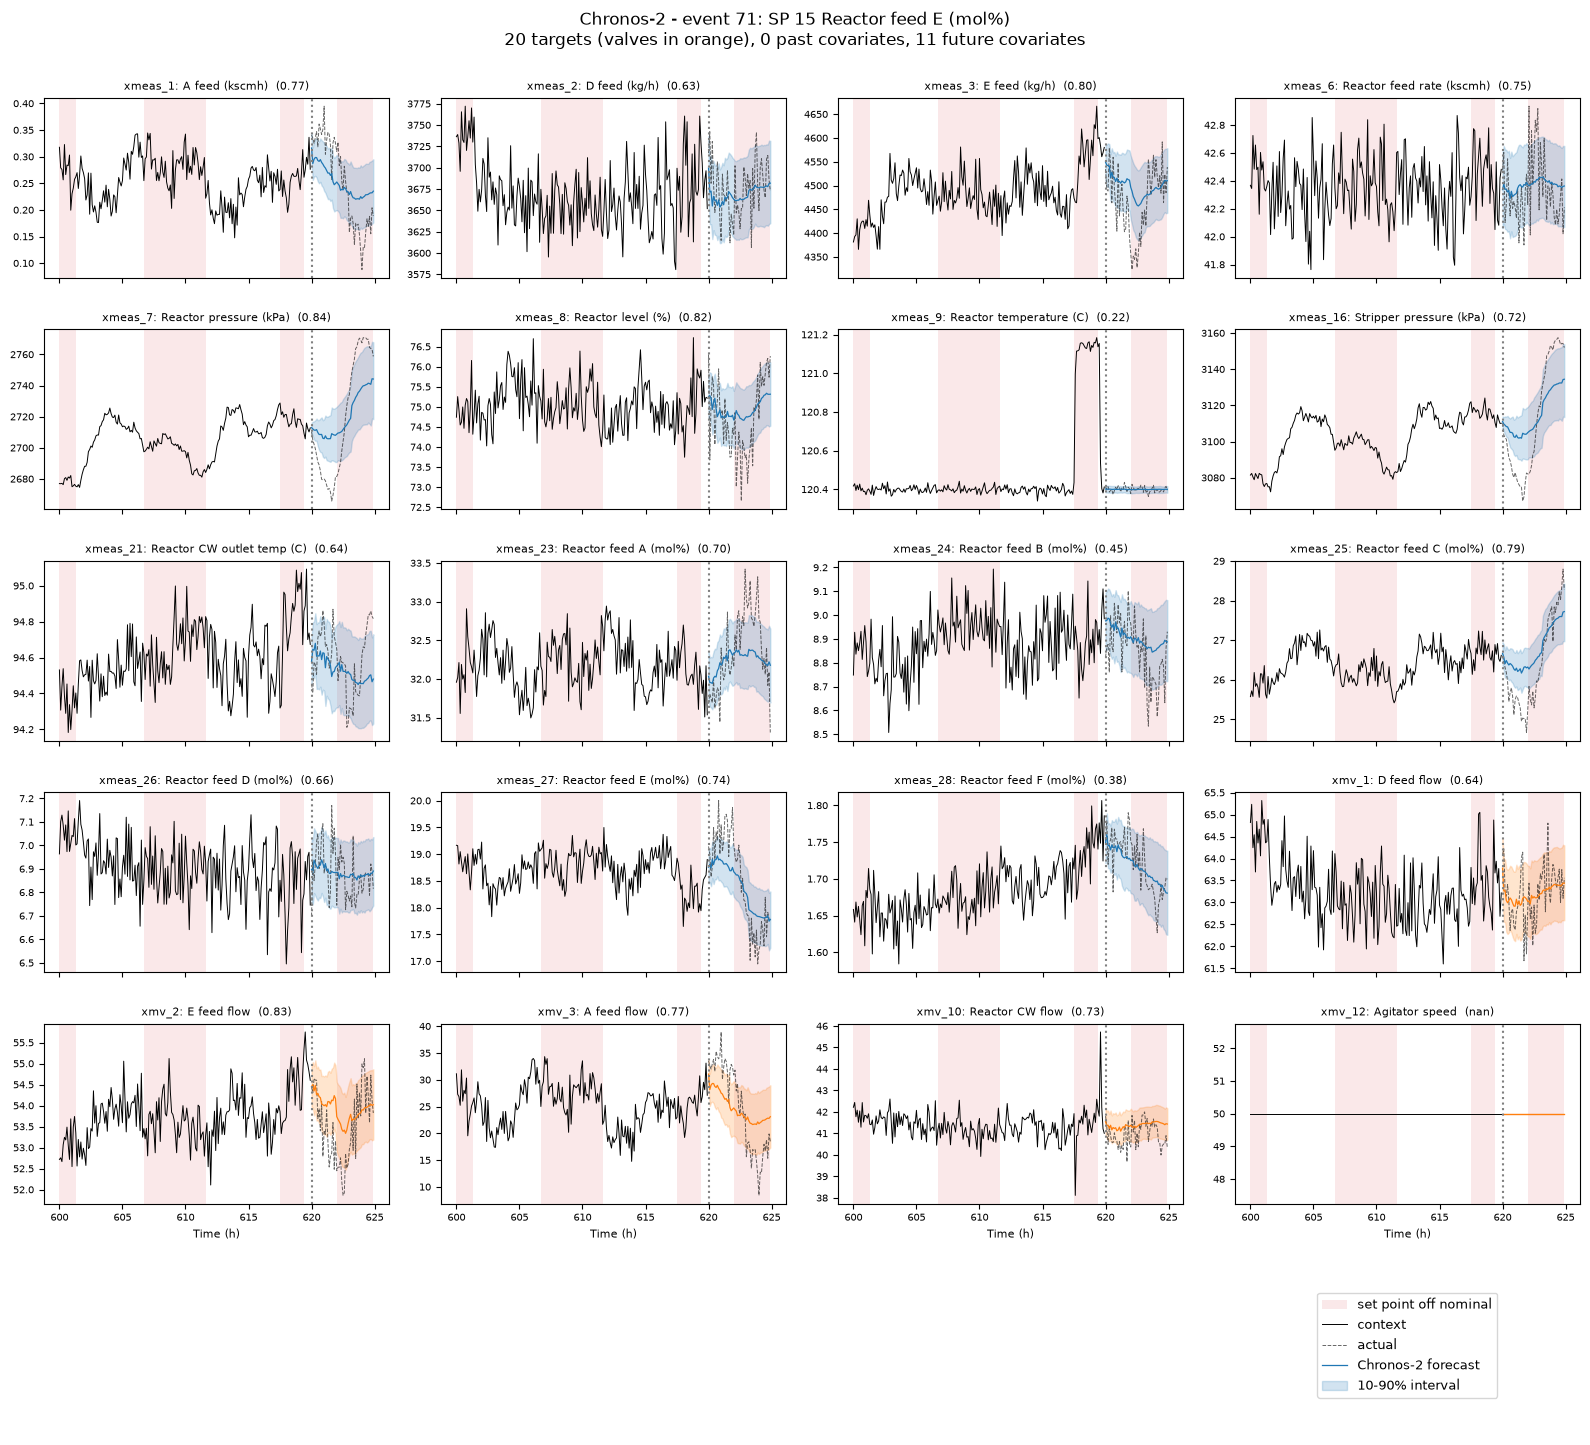

In [10]:
# Plot every target
lead = context_df.iloc[-PLOT_LEAD_IN:]
shown = pd.concat([lead, truth_df])

n_rows = -(-(len(TARGETS) + 1) // 4)
fig, axes = plt.subplots(n_rows, 4, figsize=(16, 2.4 * n_rows), sharex=True)
axes = axes.ravel()
for ax, col in zip(axes, TARGETS):
    color = "tab:orange" if col.startswith("xmv") else "tab:blue"
    ax.fill_between(shown["time_h"], 0, 1, where=shown["off_nominal"], color="tab:red", alpha=0.1,
                    transform=ax.get_xaxis_transform(), step="post", lw=0, label="set point off nominal")
    ax.plot(lead["time_h"], lead[col], color="black", lw=0.7, label="context")
    ax.plot(truth_df["time_h"], truth_df[col], color="black", lw=0.7, ls="--", alpha=0.6, label="actual")
    ax.plot(truth_df["time_h"], forecast[col], color=color, lw=0.9, label=f"{MODEL_LABEL} forecast")
    ax.fill_between(truth_df["time_h"], lower[col], upper[col], color=color, alpha=0.2, label="10-90% interval")
    ax.axvline(truth_df["time_h"].iloc[0], color="gray", ls=":")
    ax.set_title(f"{col}: {LABELS[col]}  ({accuracy.loc[col, 'scaled MAE (all)']:.2f})", fontsize=8)
    ax.tick_params(labelsize=7)
for ax in axes[len(TARGETS) - 4:len(TARGETS)]:
    ax.xaxis.set_tick_params(labelbottom=True)
    ax.set_xlabel("Time (h)", fontsize=8)
for ax in axes[len(TARGETS):]:
    ax.axis("off")
handles, labels = axes[0].get_legend_handles_labels()
axes[-1].legend(handles, labels, loc="center", fontsize=9)
fig.suptitle(f"{MODEL_LABEL} - event {EVENT_INDEX}: SP {event_sp} {LABELS[f'sp_{event_sp}']}\n"
             f"{len(TARGETS)} targets (valves in orange), {len(PAST_COVARIATES)} past covariates, "
             f"{len(FUTURE_COVARIATES)} future covariates", y=1.0)
fig.tight_layout()

In [11]:
# Save results
RESULTS_FILE = "Results/setpointforecast_chronos2_reactor.h5"

os.makedirs("Results", exist_ok=True)
with h5py.File(RESULTS_FILE, "w") as f:
    f.attrs["model"] = MODEL_LABEL
    f.attrs["settings"] = json.dumps({
        "data_file": DATA_FILE,
        "event_index": EVENT_INDEX,
        "split": int(SPLIT),
        "horizon": int(HORIZON),
        "past_covariates": PAST_COVARIATES,
        "future_covariates": FUTURE_COVARIATES,
    })

    # Accuracy table
    f.create_dataset("variable", data=list(accuracy.index))
    f.create_dataset("description", data=list(accuracy["description"]))
    for name in accuracy.columns:
        if name != "description":
            f.create_dataset(name, data=accuracy[name].to_numpy())

    # Forecasts, actual values and the end of the context
    f.create_dataset("time_h", data=truth_df["time_h"].to_numpy())
    f.create_dataset("off_nominal", data=truth_df["off_nominal"].to_numpy())
    f.create_dataset("context_time_h", data=lead["time_h"].to_numpy())
    for col in TARGETS:
        f.create_dataset(f"forecast/{col}", data=forecast[col])
        f.create_dataset(f"lower/{col}", data=lower[col])
        f.create_dataset(f"upper/{col}", data=upper[col])
        f.create_dataset(f"actual/{col}", data=truth_df[col].to_numpy())
        f.create_dataset(f"context/{col}", data=lead[col].to_numpy())
print(f"Saved {MODEL_LABEL} results to {RESULTS_FILE}")

Saved Chronos-2 results to Results/setpointforecast_chronos2_reactor.h5
